In [9]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings('ignore')

In [10]:
df = pd.read_csv("Indian_Liver_Patient_Dataset_(ILPD).csv")

In [11]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (583, 11)


,Age,Gender,TotalBilirubin,Direct Bilirubin,AlkalinePhosphotase,AlamineAminotransferase,AspartateAminotransferase,TotalProtiens,Albumin,AlbuminandGlobulinRatio,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        583 non-null    int64  
 1   Gender                     583 non-null    str    
 2   TotalBilirubin             583 non-null    float64
 3   Direct Bilirubin           583 non-null    float64
 4   AlkalinePhosphotase        583 non-null    int64  
 5   AlamineAminotransferase    583 non-null    int64  
 6   AspartateAminotransferase  583 non-null    int64  
 7   TotalProtiens              583 non-null    float64
 8   Albumin                    583 non-null    float64
 9   AlbuminandGlobulinRatio    579 non-null    float64
 10  Target                     583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB


In [13]:
df.describe()

,Age,TotalBilirubin,Direct Bilirubin,AlkalinePhosphotase,AlamineAminotransferase,AspartateAminotransferase,TotalProtiens,Albumin,AlbuminandGlobulinRatio,Target
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [14]:
df.describe(include='all')

,Age,Gender,TotalBilirubin,Direct Bilirubin,AlkalinePhosphotase,AlamineAminotransferase,AspartateAminotransferase,TotalProtiens,Albumin,AlbuminandGlobulinRatio,Target
count,583.000000,583,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,44.746141,NaN,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,NaN,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,NaN,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,NaN,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,NaN,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,NaN,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000


In [15]:
missing_values = df.isnull().sum()

missing_values

Age                          0
Gender                       0
TotalBilirubin               0
Direct Bilirubin             0
AlkalinePhosphotase          0
AlamineAminotransferase      0
AspartateAminotransferase    0
TotalProtiens                0
Albumin                      0
AlbuminandGlobulinRatio      4
Target                       0
dtype: int64

In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_df.sort_values(by='Missing Count', ascending=False)

,Missing Count,Missing Percentage
AlbuminandGlobulinRatio,4,0.686106
Gender,0,0.000000
Age,0,0.000000
TotalBilirubin,0,0.000000
Direct Bilirubin,0,0.000000
AlamineAminotransferase,0,0.000000
AlkalinePhosphotase,0,0.000000
AspartateAminotransferase,0,0.000000
TotalProtiens,0,0.000000
Albumin,0,0.000000


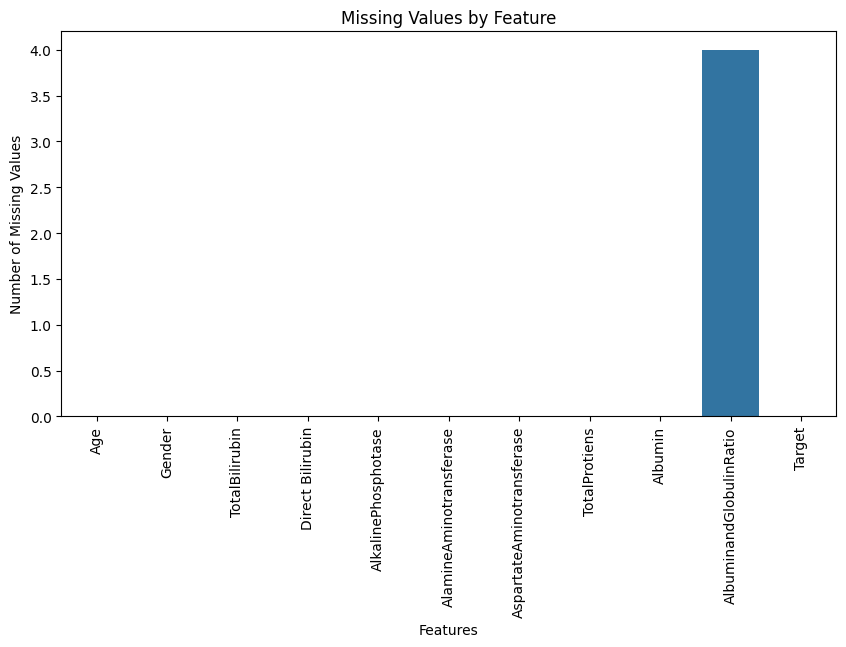

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_df.index,
    y=missing_df['Missing Count']
)

plt.xticks(rotation=90)
plt.title("Missing Values by Feature")
plt.ylabel("Number of Missing Values")
plt.xlabel("Features")
plt.show()

In [18]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 13


In [19]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

Age: 72 unique values
Gender: 2 unique values
TotalBilirubin: 113 unique values
Direct Bilirubin: 80 unique values
AlkalinePhosphotase: 263 unique values
AlamineAminotransferase: 152 unique values
AspartateAminotransferase: 177 unique values
TotalProtiens: 58 unique values
Albumin: 40 unique values
AlbuminandGlobulinRatio: 69 unique values
Target: 2 unique values


In [20]:
df['Target'].value_counts(normalize=True) * 100

Target
1    71.35506
2    28.64494
Name: proportion, dtype: float64

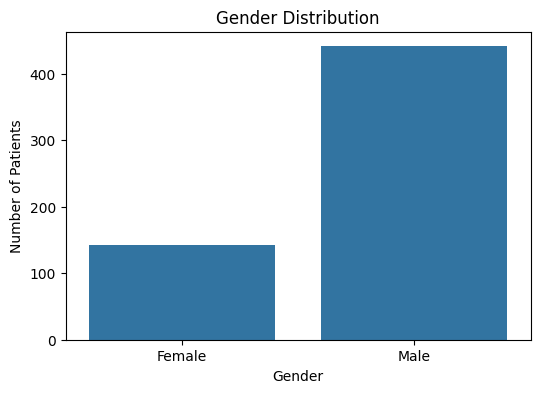

In [21]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Gender')

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

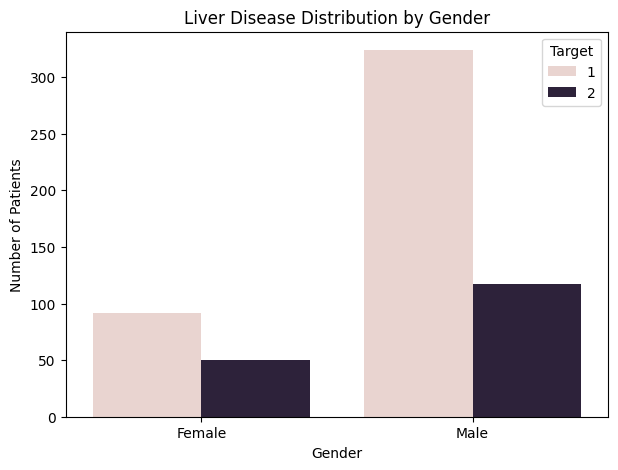

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Gender',
    hue='Target'
)

plt.title("Liver Disease Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

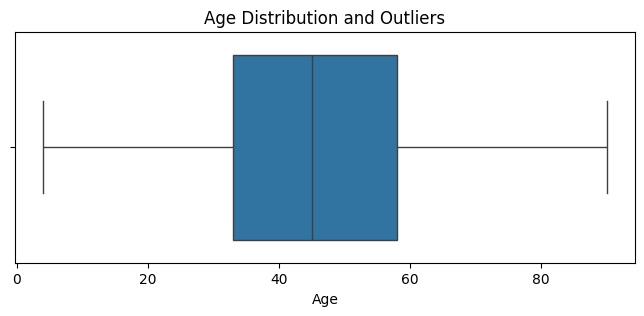

In [23]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df['Age'])

plt.title("Age Distribution and Outliers")
plt.xlabel("Age")

plt.show()

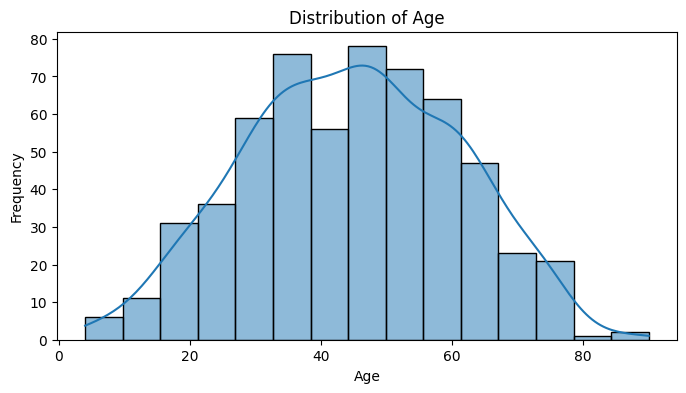

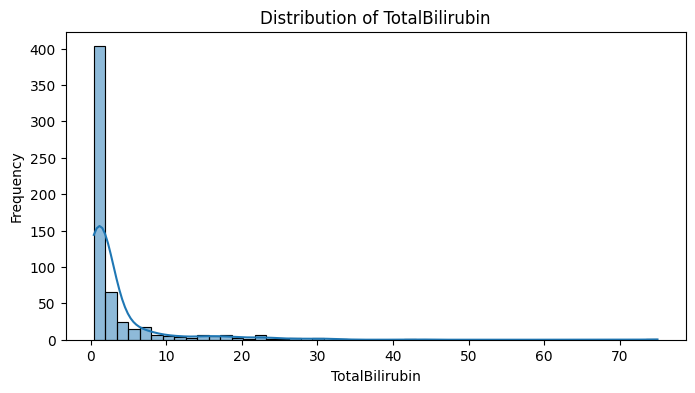

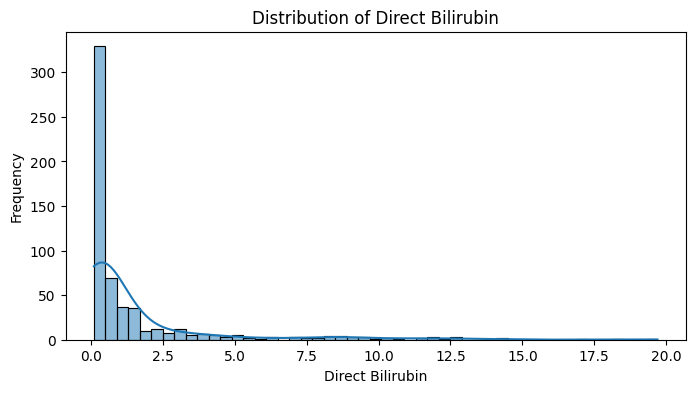

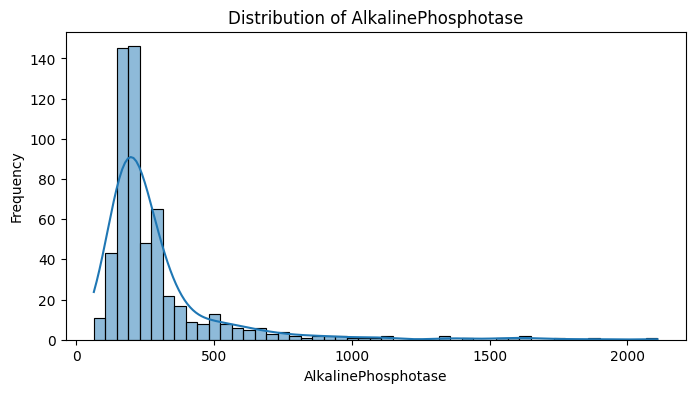

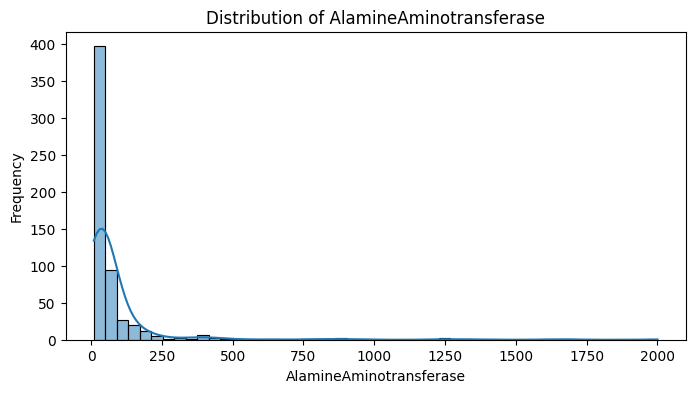

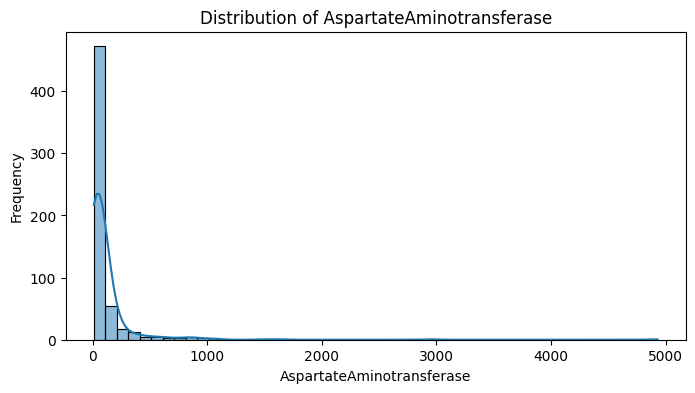

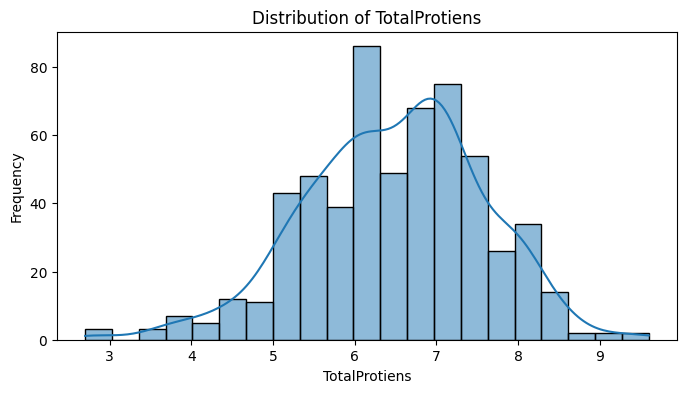

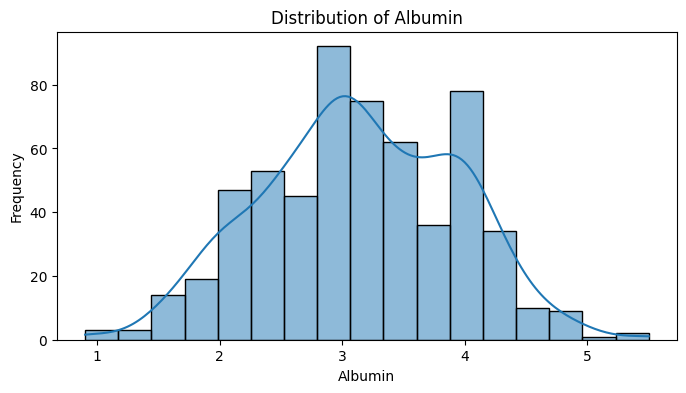

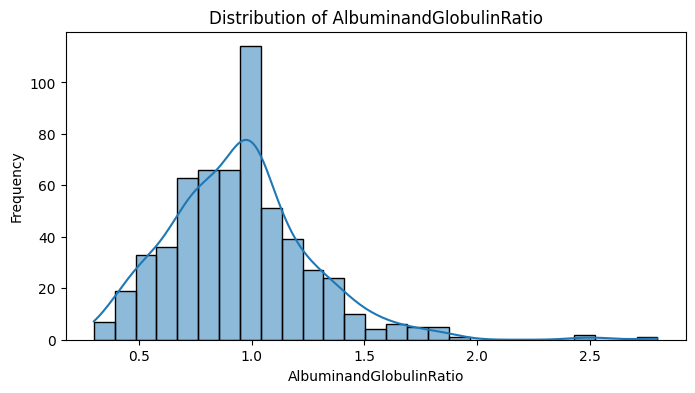

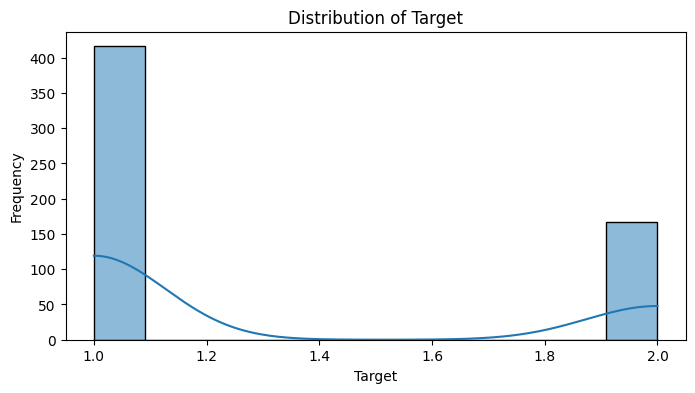

In [24]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

numerical_columns

for column in numerical_columns:
    
    plt.figure(figsize=(8, 4))
    
    sns.histplot(
        data=df,
        x=column,
        kde=True
    )
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.show()

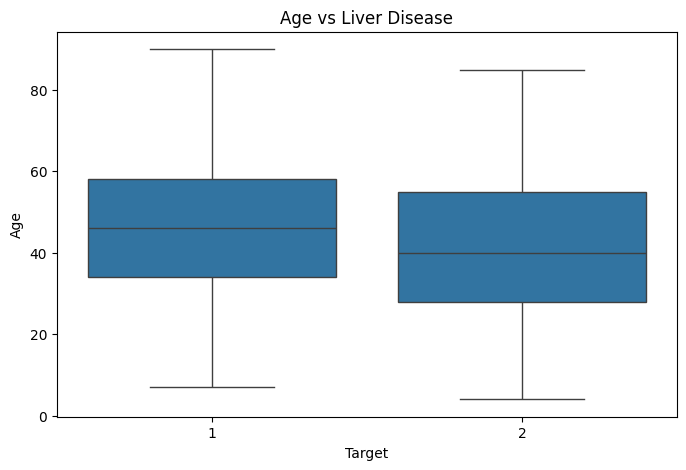

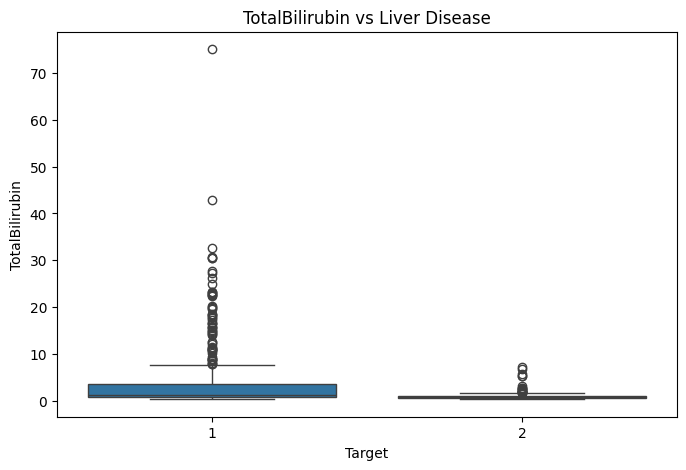

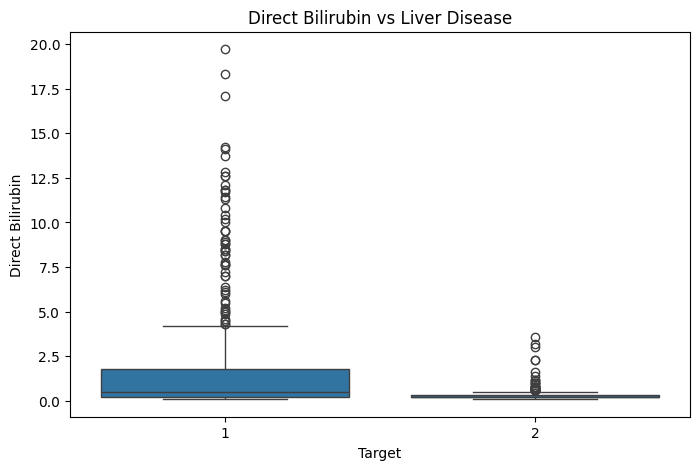

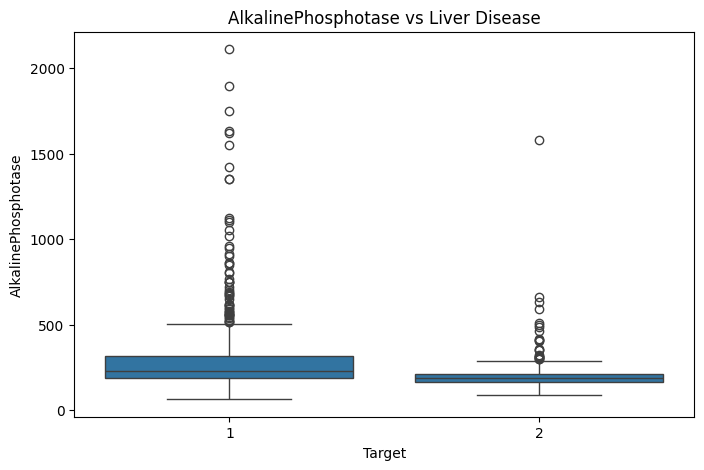

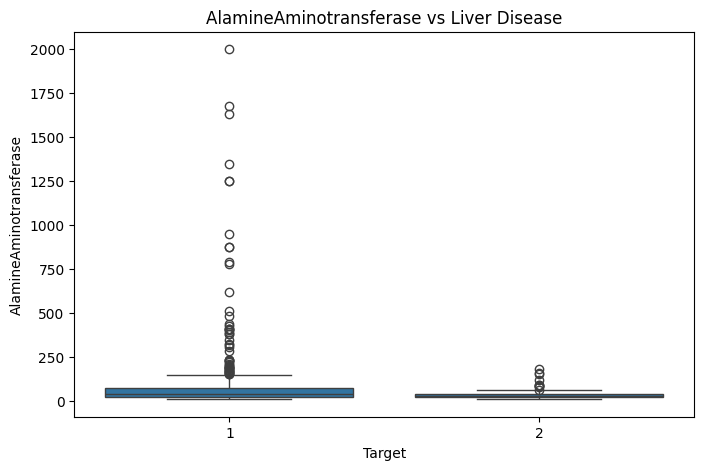

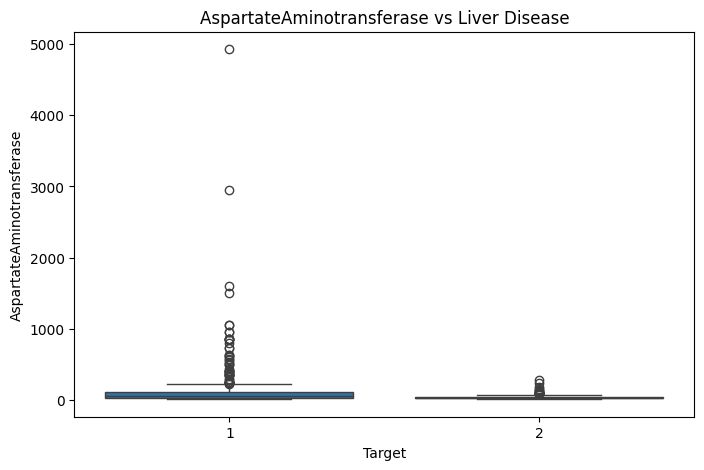

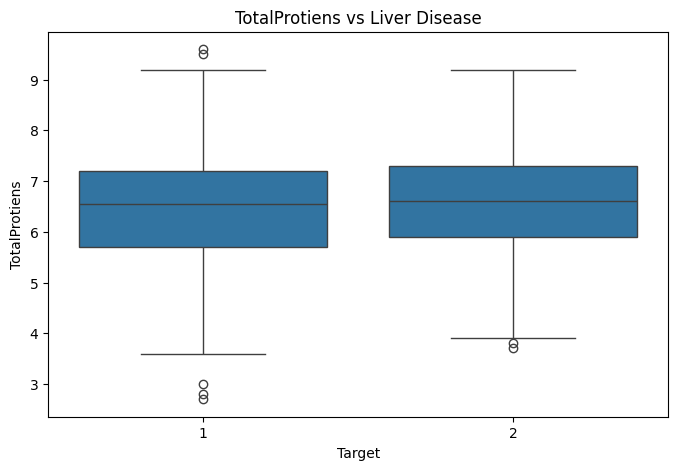

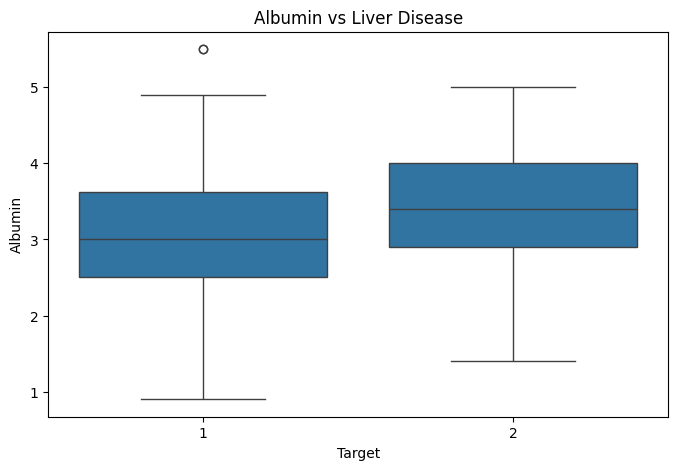

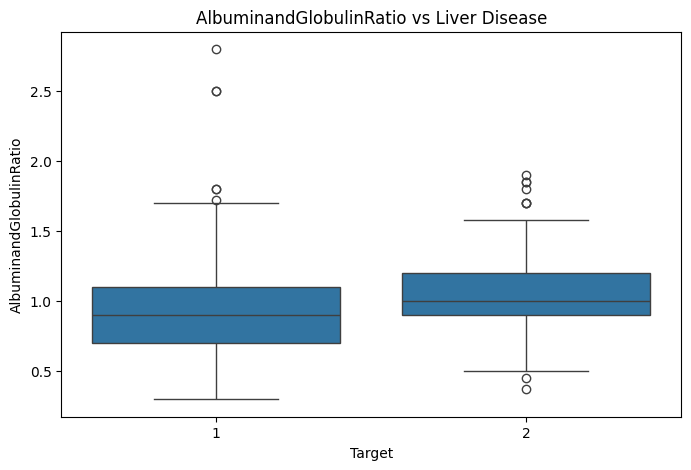

In [25]:
for column in numerical_columns:
    
    if column != 'Target':
        
        plt.figure(figsize=(8, 5))
        
        sns.boxplot(
            data=df,
            x='Target',
            y=column
        )
        
        plt.title(f"{column} vs Liver Disease")
        plt.xlabel("Target")
        plt.ylabel(column)
        
        plt.show()

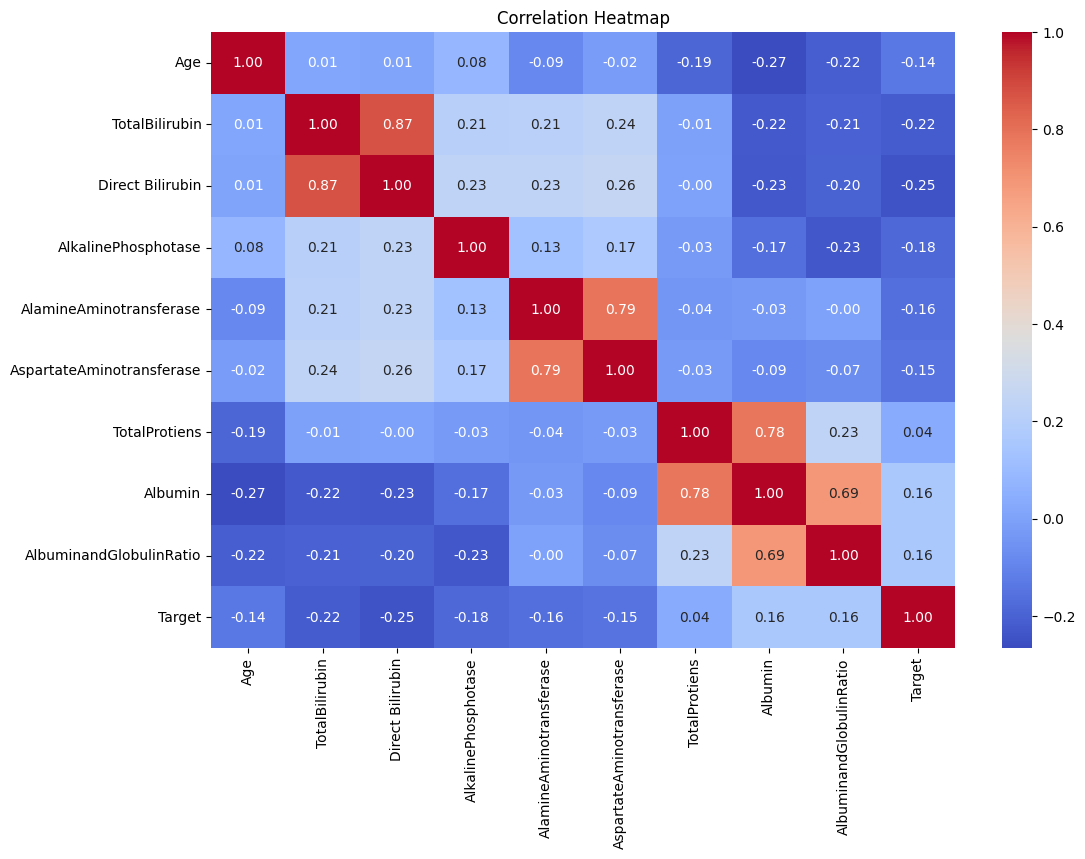

In [27]:
correlation = df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [28]:
target_correlation = correlation['Target'].sort_values(
    ascending=False
)

target_correlation

Target                       1.000000
AlbuminandGlobulinRatio      0.163131
Albumin                      0.161388
TotalProtiens                0.035008
Age                         -0.137351
AspartateAminotransferase   -0.151934
AlamineAminotransferase     -0.163416
AlkalinePhosphotase         -0.184866
TotalBilirubin              -0.220208
Direct Bilirubin            -0.246046
Name: Target, dtype: float64

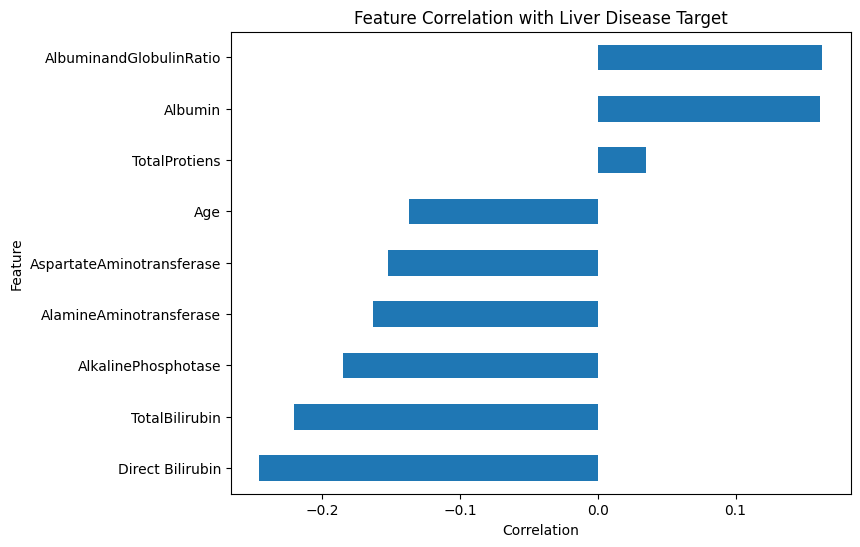

In [29]:
plt.figure(figsize=(8, 6))

target_correlation.drop('Target').sort_values().plot(
    kind='barh'
)

plt.title("Feature Correlation with Liver Disease Target")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

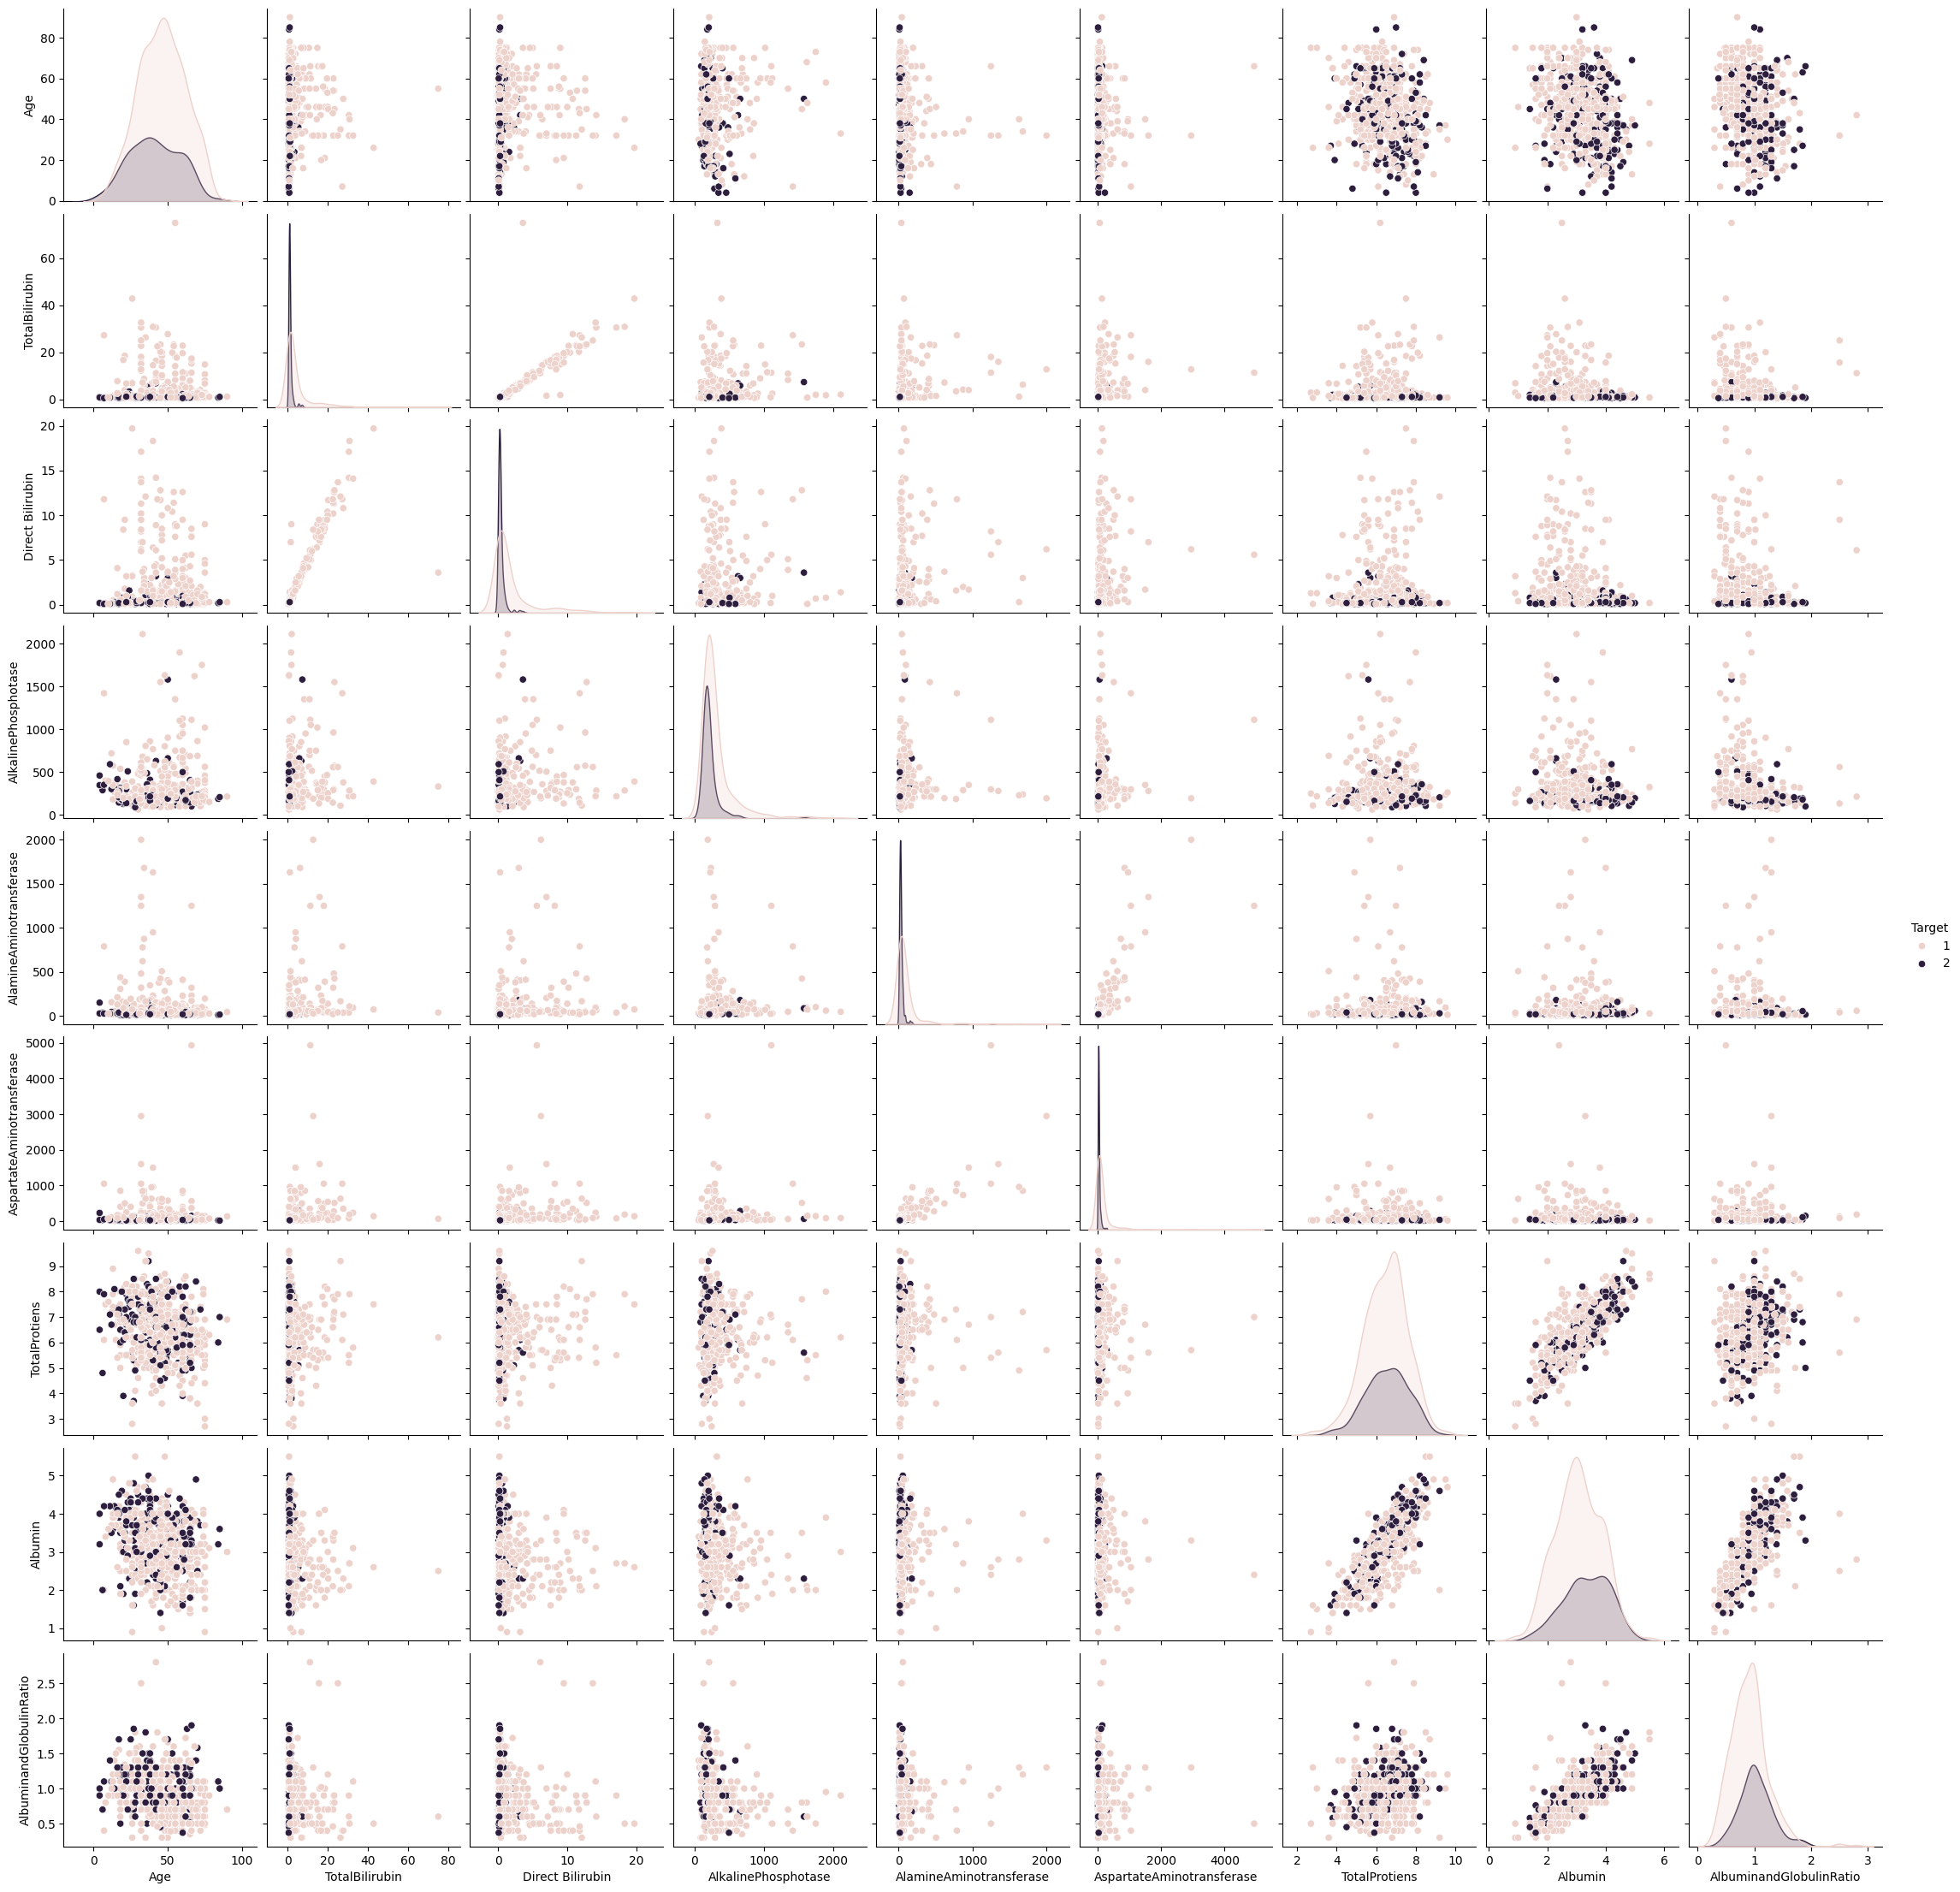

In [30]:
sns.pairplot(
    df,
    hue='Target',
    diag_kind='kde'
)

plt.show()